In [1]:
import random

random.seed(42)
seeds = random.sample(range(1,2024),5)
seeds

[1310, 229, 52, 1519, 564]

## Running script

In [ ]:
# !bash /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/run_scripts/run_genetic_perturbation_benchmark_exps.sh

### Export results

In [ ]:
import pandas as pd 
import wandb
api = wandb.Api()

# Project is specified by <entity/project-name>
runs = api.runs("lynnymli/norman")

result_df=pd.DataFrame()
i = 0
for run in runs: 
    if run.summary._json_dict == {}: continue
    for seed in seeds:
        if (str(seed) in run.name) and ('model_compare_5splits' in run.name):
            # print(run.name)
            if i == 0:
                result_df = pd.DataFrame(run.summary._json_dict).reset_index(drop=True).T.sort_index()
                result_df.columns = [run.name]
            else:
                result_df[run.name] = pd.DataFrame(run.summary._json_dict).T.sort_index().values
            i += 1

result_df = result_df.T
result_df = result_df.drop(columns=['_runtime', '_step', '_timestamp', '_wandb'])

models = ["No-Perturb", "PseAAC", "ESM2", "OntoProtein", "GEARS", "UniPert"]

assert result_df.shape[0] == len(models) * len(seeds)

result_df['model'] = result_df.index.map(lambda idx: idx.split('_')[0] if '_' in idx else idx)
result_df['seed'] = result_df.index.map(lambda idx: int(idx.split('_')[1]) if '_' in idx else idx)

result_df

,test_combo_seen0_frac_opposite_direction_top20_non_dropout,test_combo_seen0_frac_sigma_below_1_non_dropout,test_combo_seen0_mse,test_combo_seen0_mse_de,test_combo_seen0_mse_top20_de_non_dropout,test_combo_seen0_pearson,test_combo_seen0_pearson_de,test_combo_seen0_pearson_delta,test_combo_seen1_frac_opposite_direction_top20_non_dropout,test_combo_seen1_frac_sigma_below_1_non_dropout,...,train_de_pearson,train_mse,train_pearson,training_loss,val_de_mse,val_de_pearson,val_mse,val_pearson,model,seed
ESM2_564_model_compare_5splits_0803,0.270000,0.605000,0.007958,0.394611,0.537584,0.976737,0.711504,0.391340,0.229592,0.716327,...,0.941481,0.002473,0.993466,0.508690,0.096406,0.866242,0.004682,0.987806,ESM2,564
ESM2_1310_model_compare_5splits_0803,0.223077,0.607692,0.013156,0.392819,0.539843,0.963773,0.790163,0.487540,0.175000,0.771000,...,0.932754,0.002204,0.993917,0.473516,0.208109,0.902815,0.004585,0.987082,ESM2,1310
ESM2_52_model_compare_5splits_0803,0.182143,0.728571,0.005453,0.328523,0.342412,0.984328,0.895646,0.510829,0.155357,0.773214,...,0.942486,0.002286,0.993879,0.529638,0.219929,0.926776,0.004919,0.986586,ESM2,52
ESM2_1519_model_compare_5splits_0803,0.140000,0.880000,0.007948,0.105461,0.130275,0.978334,0.966700,0.515545,0.151111,0.830000,...,0.928765,0.002780,0.992846,0.522520,0.306179,0.912839,0.021503,0.951292,ESM2,1519
ESM2_229_model_compare_5splits_0803,0.300000,0.437500,0.010282,0.562560,0.715904,0.969390,0.619501,0.449857,0.194792,0.741667,...,0.921453,0.001816,0.994926,0.414024,0.364652,0.845550,0.006498,0.981292,ESM2,229
GEARS_52_model_compare_5splits_0803,0.157143,0.775000,0.005170,0.290004,0.309156,0.985126,0.907682,0.485731,0.137500,0.775000,...,0.942209,0.002334,0.993800,0.450526,0.285186,0.869000,0.004363,0.987436,GEARS,52
GEARS_564_model_compare_5splits_0803,0.235000,0.685000,0.006882,0.240203,0.339096,0.980071,0.743515,0.473431,0.225510,0.743878,...,0.944158,0.002361,0.993733,0.524231,0.113965,0.866422,0.003276,0.991054,GEARS,564
GEARS_1310_model_compare_5splits_0803,0.200000,0.565385,0.011136,0.423148,0.666445,0.967515,0.711912,0.470322,0.140000,0.797000,...,0.936291,0.002298,0.993720,0.533671,0.148915,0.914856,0.003691,0.989728,GEARS,1310
GEARS_1519_model_compare_5splits_0803,0.170000,0.940000,0.004446,0.079998,0.104373,0.988015,0.964475,0.569192,0.140000,0.827778,...,0.927935,0.002537,0.993371,0.421345,0.315007,0.863050,0.007734,0.979502,GEARS,1519
GEARS_229_model_compare_5splits_0803,0.087500,0.362500,0.010191,0.431994,0.718948,0.968920,0.660863,0.570463,0.162500,0.743750,...,0.918107,0.002023,0.994362,0.583718,0.438768,0.813595,0.007157,0.979146,GEARS,229


In [ ]:
result_df = result_df.drop(columns=['seed'])

In [ ]:
overall_results = result_df.groupby(['model']).mean()
metrics = ["test_combo_seen0_pearson_delta", "test_combo_seen0_mse_de", "test_combo_seen0_frac_opposite_direction_top20_non_dropout",
            "test_combo_seen1_pearson_delta", "test_combo_seen1_mse_de", "test_combo_seen1_frac_opposite_direction_top20_non_dropout",
           "test_combo_seen2_pearson_delta", "test_combo_seen2_mse_de", "test_combo_seen2_frac_opposite_direction_top20_non_dropout", ]
metric_rank = pd.DataFrame(index=models)
for metric in metrics:
    if ('pearson' in metric) or ('sigma_below_1' in metric):
        metric_rank[metric] = overall_results[metric].rank(ascending=False, method='min').astype(int)
    else:
        metric_rank[metric] = overall_results[metric].rank(ascending=True, method='min').astype(int)
metric_rank['overall_rank'] = metric_rank.sum(axis=1).astype(int).rank(ascending=True, method='min').astype(int)
metric_rank

,test_combo_seen0_pearson_delta,test_combo_seen0_mse_de,test_combo_seen0_frac_opposite_direction_top20_non_dropout,test_combo_seen1_pearson_delta,test_combo_seen1_mse_de,test_combo_seen1_frac_opposite_direction_top20_non_dropout,test_combo_seen2_pearson_delta,test_combo_seen2_mse_de,test_combo_seen2_frac_opposite_direction_top20_non_dropout,overall_rank
No-Perturb,6,6,6,6,6,6,6,6,6,6
PseAAC,4,2,4,5,4,4,5,4,5,5
ESM2,5,5,5,4,5,5,1,1,1,4
OntoProtein,3,3,2,3,1,3,4,2,3,2
GEARS,2,4,3,1,2,2,3,3,4,2
UniPert,1,1,1,2,3,1,2,5,2,1


## funkyheatmap plot

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import matplotlib
import matplotlib as mpl
from matplotlib.colors import Normalize

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])

plt.rcParams.update({'font.size': 16})


In [66]:
# ! pip install funkyheatmappy

In [27]:
palette1 = 'Blues'
palette2 = 'Oranges'
palette3 = 'Greens'

In [46]:
column_lists = [
  ["id", "group", "name", "geom", "options", "palette"],
  ["id", np.nan, "", "text", {"ha": 0, "width": 2}, np.nan],
  ["test_combo_seen0_pearson_delta", "Seen 0", "PCC", "funkyrect", dict(), palette1],
  ["test_combo_seen0_mse_de", "Seen 0", "MSE", "funkyrect", dict(), palette1],
  ["test_combo_seen0_frac_opposite_direction_top20_non_dropout", "Seen 0", "FOD", "funkyrect", dict(), palette1],
  ["test_combo_seen1_pearson_delta", "Seen 1", "PCC", "funkyrect", dict(), palette2],
  ["test_combo_seen1_mse_de", "Seen 1", "MSE", "funkyrect", dict(), palette2],
  ["test_combo_seen1_frac_opposite_direction_top20_non_dropout", "Seen 1", "FOD", "funkyrect", dict(), palette2],
  ["test_combo_seen2_pearson_delta", "Seen 2", "PCC", "funkyrect", dict(), palette3],
  ["test_combo_seen2_mse_de", "Seen 2", "MSE", "funkyrect",  dict(), palette3],
  ["test_combo_seen2_frac_opposite_direction_top20_non_dropout", "Seen 2", "FOD", "funkyrect", dict(), palette3],
  ['overall_rank', "Overall", "Overall", "bar", {"width": 3, "legend": False}, "palette4"],
]

column_info = pd.DataFrame(column_lists[1:], columns=column_lists[0])
column_info.index = column_info["id"]
column_info

,id,group,name,geom,options,palette
id,,,,,,
id,id,NaN,,text,"{'ha': 0, 'width': 2}",NaN
test_combo_seen0_pearson_delta,test_combo_seen0_pearson_delta,Seen 0,PCC,funkyrect,{},Blues
test_combo_seen0_mse_de,test_combo_seen0_mse_de,Seen 0,MSE,funkyrect,{},Blues
test_combo_seen0_frac_opposite_direction_top20_non_dropout,test_combo_seen0_frac_opposite_direction_top20...,Seen 0,FOD,funkyrect,{},Blues
test_combo_seen1_pearson_delta,test_combo_seen1_pearson_delta,Seen 1,PCC,funkyrect,{},Oranges
test_combo_seen1_mse_de,test_combo_seen1_mse_de,Seen 1,MSE,funkyrect,{},Oranges
test_combo_seen1_frac_opposite_direction_top20_non_dropout,test_combo_seen1_frac_opposite_direction_top20...,Seen 1,FOD,funkyrect,{},Oranges
test_combo_seen2_pearson_delta,test_combo_seen2_pearson_delta,Seen 2,PCC,funkyrect,{},Greens
test_combo_seen2_mse_de,test_combo_seen2_mse_de,Seen 2,MSE,funkyrect,{},Greens


In [31]:
column_groups = pd.DataFrame(columns=["Category", "group", "palette"],
                              data = [["Overall", "Overall", "palette4"],
                                      ["Seen 0", "Seen 0", palette1],
                                      ["Seen 1", "Seen 1", palette2],
                                      ["Seen 2", "Seen 2", palette3],
                                      ]
                            )
column_groups

,Category,group,palette
0,Overall,Overall,palette4
1,Seen 0,Seen 0,Blues
2,Seen 1,Seen 1,Oranges
3,Seen 2,Seen 2,Greens


/data/home/lynnymli/miniconda3/envs/R/lib/python3.12/site-packages/funkyheatmappy/verify_column_info.py:79: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['id' 'test_combo_seen0_pearson_delta' 'test_combo_seen0_mse_de'
 'test_combo_seen0_frac_opposite_direction_top20_non_dropout'
 'test_combo_seen1_pearson_delta' 'test_combo_seen1_mse_de'
 'test_combo_seen1_frac_opposite_direction_top20_non_dropout'
 'test_combo_seen2_pearson_delta' 'test_combo_seen2_mse_de'
 'test_combo_seen2_frac_opposite_direction_top20_non_dropout'
 'overall_rank']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_color"]), "id_color"] = column_info["id"] # if nan, replace by id, except if text or image
/data/home/lynnymli/miniconda3/envs/R/lib/python3.12/site-packages/funkyheatmappy/verify_column_info.py:89: FutureWarning: Setting an item of incompatib

No legends were provided, trying to automatically infer legends.
Some palettes were not used in the column info, adding legends for them:Oranges, Greens, Blues, palette4
Legend {'title': 'Oranges', 'palette': 'Oranges', 'enabled': True} did not contain a geom, inferring from the column_info.
Legend {'title': 'Oranges', 'palette': 'Oranges', 'enabled': True, 'geom': 'funkyrect'} did not contain labels, inferring from the geom.
Legend {'title': 'Oranges', 'palette': 'Oranges', 'enabled': True, 'geom': 'funkyrect', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1']} did not contain size, inferring from the labels.
Legend {'title': 'Oranges', 'palette': 'Oranges', 'enabled': True, 'geom': 'funkyrect', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1'], 'size': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0]} did not contain color, inferring from the palette.
Legend {'title': 'Greens', 'palette': 'Gree

/data/home/lynnymli/miniconda3/envs/R/lib/python3.12/site-packages/matplotlib/image.py:941: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [("x", [extent[0], extent[1]]),
/data/home/lynnymli/miniconda3/envs/R/lib/python3.12/site-packages/matplotlib/image.py:942: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ("y", [extent[2], extent[3]])],


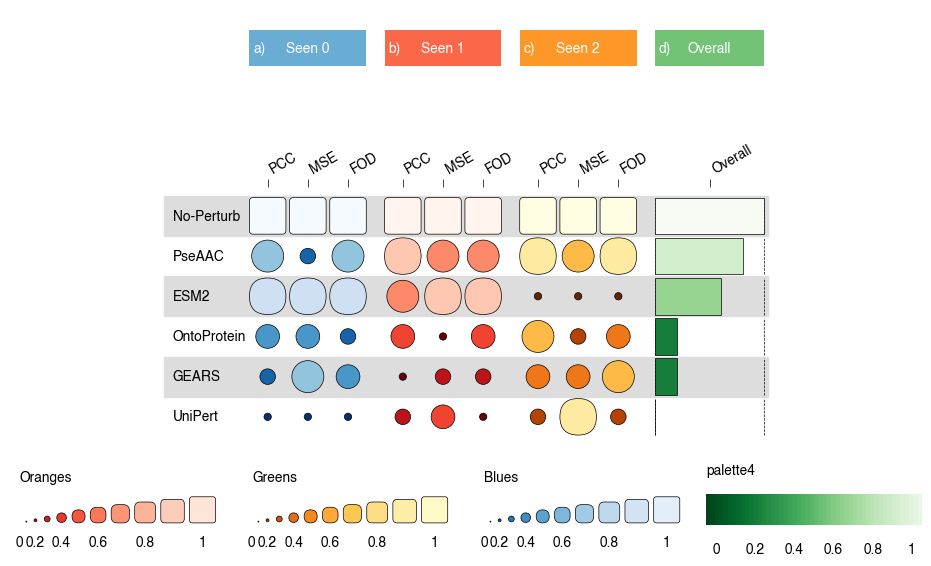

In [ ]:
import funkyheatmappy

res = metric_rank.reset_index().rename(columns={"index": "id"})
fig = funkyheatmappy.funky_heatmap(res, column_info=column_info, column_groups=column_groups)